# Causal Inference on Startup Failures

**Dataset:** *Startup Failures* (Kaggle, CC BY-NC 4.0), cleaned into `startups_clean.csv` (356 startups). The cleaning steps are in `cleaning_causal_inference_startups.ipynb`, summary of the process below.

**Context:** Though i could not reuse my previous dataset I wished to remain in the domain of startups. This time I found a public dataset which lists companies who have failed as well as their sector of activity, years of operation, funding figures and 13 binary failure-cause flags.

## Data cleaning summary

The cleaning code is in `causal_inference_startups.ipynb`, which produces `startups_clean.csv` (356 startups). What was done:

- Combined the 6 sector files into 409 rows. 
- The Food and Services file is missing 4 of the flags and has an extra column. I dropped the extra column and filled the missing flags with 0, which really means "not recorded" for those rows. I don't use any of those flags in the models.
- Five companies appeared in more than one sector file (Bitpass, Clinkle, Jawbone, Sprig, Zume). I kept the first occurrence of each, leaving 403 rows.
- I pulled founding year, end year and lifespan out of the `Years of Operation` column, which comes in two formats.
- I converted the funding column to millions of dollars.
- I dropped 46 rows that are products of bigger companies, for example "$0 (Coinbase-funded)" or "$1.7B (Dropbox)", because the funding figure belongs to the parent company and not the startup itself. 
- I dropped one row whose funding could not be read ("$lowM"). This leaves 356 startups.

Variables created:

- `lifespan`: years of operation, used as the outcome.
- `high_funding`: 1 if the startup raised more than the median of $20M (176 high, 180 low), used as the treatment.
- `era`: founded up to 2008 (84 startups), 2009 to 2014 (234), or 2015 and later (38).
- `hardware` (49), `physical_ops` (36) and `b2b` (60): business-model labels based on keywords in the `What They Did` text, which I then checked and corrected by hand. `consumer_digital` (217) is everything else (apps, software and e-commerce for consumers).

### Loading cleaned data

In [46]:
import pandas as pd
import numpy as np

df = pd.read_csv("startups_clean.csv")
print(df.shape)
df.head()

(356, 27)


,Name,Sector,What They Did,founding_year,end_year,lifespan,era,hardware,physical_ops,b2b,...,Poor Market Fit,Acquisition Stagnation,Platform Dependency,Monetization Failure,Niche Limits,Execution Flaws,Trend Shifts,Toxicity/Trust Issues,Regulatory Pressure,Overhype
0,Avant,Finance and Insurance,Online personal loans,2012,2023,11,2009_2014,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Bitpass,Finance and Insurance,Micropayments platform,2002,2008,6,up_to_2008,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,Cake Financial,Finance and Insurance,Portfolio tracking tool,2006,2011,5,up_to_2008,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,Circle,Finance and Insurance,Crypto payments and stablecoin,2013,2023,10,2009_2014,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,Clarity Money,Finance and Insurance,Personal finance app,2016,2022,6,2015_plus,0,0,0,...,0,1,0,0,0,0,0,0,0,0


## First treatment: raising more funds

**Question:** Among startups that eventually failed, does raising more money *cause* them to survive longer?

**Hypothesis:** Startups with high funding survive longer than comparable startups with low funding as they secure a longer runway to maintain and expand product development and operations.

- **Outcome (target):** `lifespan`
- **Treatment:** `high_funding`
- **Confounders:** `founding_year`, `era`, `Sector`, `hardware`, `physical_ops`, `b2b`

**Confounders explained**

- `founding_year` and `era`: funding conditions changed a lot over time (dot-com years, the 2008 crisis, the 2010s boom, Covid, change in interest rates etc.). Recently founded startups also cannot have long lifespans, because the data ends around 2024.
- `Sector`: some sectors raise more money and have different survival patterns.
- Business models - `hardware`, `physical_ops`, `b2b`: Hardware and delivery businesses need more capital and fail in different ways, and B2B revenue tends to be stickier. `consumer_digital` is the baseline group, so it is not listed separately.

**Deliberately excluded:** the 13 failure-cause flags (e.g. poor market fit or monetization failure). They describe what happened after funding and may be caused by it. Controlling for them would bias the estimate.

**Limitations:** every startup in the dataset failed, so results apply only to failed startups. Many many other factors are not accounted for such as Founder experience, size of team, location and market size, these could bias the estimate.

In [47]:
OUTCOME = "lifespan"
TREATMENT = "high_funding"

# one-hot encoding categorical columns 
sector_dummies = pd.get_dummies(df["Sector"], prefix="sector", drop_first=True).astype(int)
era_dummies = pd.get_dummies(df["era"], prefix="era").astype(int).drop(columns="era_up_to_2008")  # baseline = up to 2008
df = pd.concat([df, sector_dummies, era_dummies], axis=1)

CONFOUNDERS = (["founding_year", "hardware", "physical_ops", "b2b"]
               + list(era_dummies.columns) + list(sector_dummies.columns))

print("Outcome:", OUTCOME)
print("Treatment:", TREATMENT, df[TREATMENT].value_counts().to_dict())
print("Confounders:", CONFOUNDERS)

Outcome: lifespan
Treatment: high_funding {0: 180, 1: 176}
Confounders: ['founding_year', 'hardware', 'physical_ops', 'b2b', 'era_2009_2014', 'era_2015_plus', 'sector_Finance and Insurance', 'sector_Health Care', 'sector_Information', 'sector_Manufacturing', 'sector_Retail Trade']


First we will check whether the treated and control groups are different before treatment.
If the confounders differ between groups, a naive comparison is biased. This is why we need causal methods.

In [48]:
print("Mean founding year by group:")
print(df.groupby(TREATMENT)["founding_year"].mean().round(1), "\n")

print("Share of startups with each feature, by treatment group:")
print(df.groupby(TREATMENT)[["hardware", "physical_ops", "b2b", "consumer_digital"]].mean().round(2), "\n")

print("Share of high-funding startups by sector:")
print(df.groupby("Sector")[TREATMENT].mean().round(2).sort_values(), "\n")

print("Share of high-funding startups by era:")
print(df.groupby("era")[TREATMENT].mean().round(2), "\n")

print("Naive (not causal) difference in lifespan:",
      round(df.loc[df[TREATMENT]==1, OUTCOME].mean() - df.loc[df[TREATMENT]==0, OUTCOME].mean(), 2), "years")

Mean founding year by group:
high_funding
0    2010.8
1    2010.2
Name: founding_year, dtype: float64 

Share of startups with each feature, by treatment group:
              hardware  physical_ops   b2b  consumer_digital
high_funding                                                
0                 0.07          0.11  0.12              0.70
1                 0.21          0.09  0.22              0.52 

Share of high-funding startups by sector:
Sector
Accommodation and Food Services    0.39
Retail Trade                       0.39
Finance and Insurance              0.41
Information                        0.44
Health Care                        0.72
Manufacturing                      0.79
Name: high_funding, dtype: float64 

Share of high-funding startups by era:
era
2009_2014     0.48
2015_plus     0.34
up_to_2008    0.60
Name: high_funding, dtype: float64 

Naive (not causal) difference in lifespan: 2.45 years


The high-funded and low-funded startups are not alike before funding enters the picture. Mean founding year is nearly the same in both groups (2010.8 vs 2010.2), but the rest differs. 
- Hardware startups are 21% of the high-funded group vs 7% of the low-funded group, and B2B is 22% vs 12%. This is the inverse of Consumer digital startups which are 52% vs 70%. This is in line with what we thought, Hardware and B2B plausibly cost more to build and may fail differently, so they could affect both funding and lifespan.
- Health Care (72%) and Manufacturing (79%) have far higher shares of high-funded startups than the other sectors (39% to 44%). So sector is tied to who gets funded, and probably to how long a startup lasts.
- Era matters too: 60% of startups founded up to 2008 are high-funded, vs 34% of those founded from 2015. Again confirming that funding conditions have changed over time.

The raw gap in average lifespan between high and low funded startups is 2.45 years (8.96 vs 6.51). But the two groups differ in sector, era and business model, so this gap mixes the effect of funding with those differences and cannot be read as the effect of funding alone. The next steps adjust for these variables.

In [49]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [50]:
import causalml, dowhy, xgboost

In [51]:
from importlib.metadata import version
print("causalml", version("causalml"))
print("dowhy", version("dowhy"))
print("xgboost", version("xgboost"))

causalml 0.18.0
dowhy 0.13
xgboost 3.4.2


### Preparing the inputs and importing learners

In [52]:
from causalml.inference.meta import LRSRegressor, XGBTRegressor

X = df[CONFOUNDERS].astype(float).values   # confounders
treatment = df[TREATMENT].values           # 1 = high funding, 0 = low funding
y = df[OUTCOME].values                     # lifespan in years

print(X.shape, treatment.shape, y.shape)

(356, 11) (356,) (356,)


### Linear regression S-learner
fits one linear regression of lifespan on funding plus the confounders, and the effect of funding is the difference between its predictions with funding set to 1 and to 0.

In [53]:
lr = LRSRegressor()
ate_lr = lr.estimate_ate(X, y=y, treatment=treatment)
print("LRSRegressor ATE:", ate_lr)

LRSRegressor ATE: (array([2.20781594]), array([1.57920634]), array([2.83642554]))


### XGBoost T-learner

fits two separate XGBoost models, one on high-funded startups and one on low-funded startups, and the effect for each startup is the difference between the two models' predictions.

In [54]:
xg = XGBTRegressor(random_state=42)
ate_xg = xg.estimate_ate(X, y=y, treatment=treatment)
print("XGBTRegressor ATE:", ate_xg)

XGBTRegressor ATE: (array([2.02143614]), array([1.56765808]), array([2.47521421]))


### CausalML results: effect of high funding on lifespan

| Estimate | Effect on lifespan (years) | Interval returned by CausalML |
|---|---|---|
| Naive difference in means (no adjustment) | 2.45 | n/a |
| linear S-learner | 2.21 | 1.58 to 2.84 |
| XGBoost T-learner | 2.02 | 1.57 to 2.48 |

**Interpretation**

- Adjusting for confounders reduces the estimated effect since the naive gap of 2.45 years falls to roughly 2.0 to 2.2 years once we control for founding year, era, sector and business model. Part of the raw difference reflects the kinds of startups that raise more money (for example, more hardware and B2B startups, and different sectors and eras), not funding itself.
- A positive effect remains as both models estimate that high funding is associated with a longer lifespan, and both intervals stay above zero.
- The two models agree - linear and the flexible model give estimates within about 0.2 years of each other, so the result does not depend on the model choice.

**Caveats**

- The estimate applies only to startups that failed, since every company in the dataset did.
- It is causal only if the 11 confounders capture the relevant differences between high and low funded startups. 
- Other metrics like founder experience, location and market size are not measured.

### Feature importance graph

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

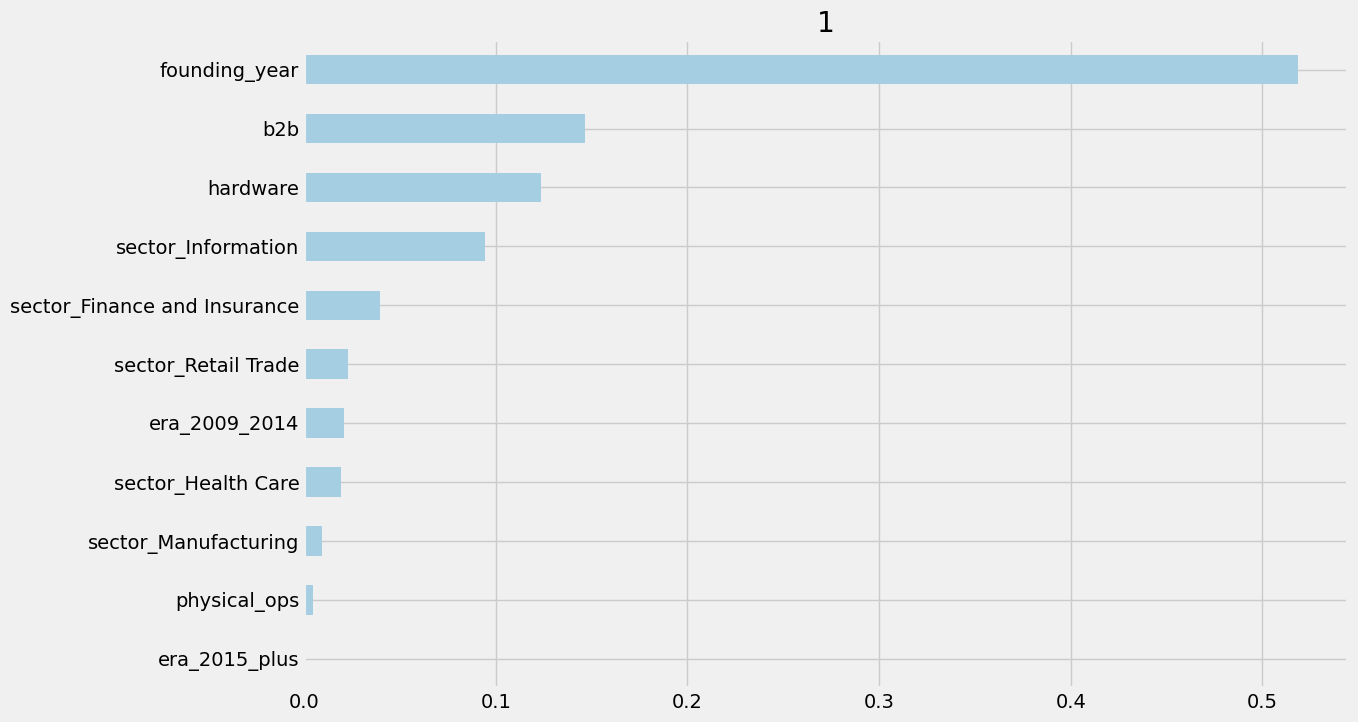

In [55]:
xg_tau = xg.fit_predict(X=X, y=y, treatment=treatment)
xg.plot_importance(X=X, tau=xg_tau, normalize=True, method='auto', features=CONFOUNDERS)

The plot ranks features by how much they explain differences in the estimated effect of funding between startups. It doesn’t rank what predicts lifespan itself. 

founding_year dominates, at roughly 0.52, more than three times anything else. The estimated benefit of funding seems to vary mostly with when the startup was founded.
b2b (~0.15) and hardware (~0.12) come next, followed by sector_Information (~0.09). The rest are small.

Importance doesn’t show direction. It says founding year matters, not whether funding helps more for older or newer startups.
Tree models tend to rate continuous features like founding_year higher than yes/no ones, because they have more places to split. 

cofounders that are near zero aren't necessarily unimportant, like era 2015+ which is built from founding_year, so the model credits founding_year instead.

#### mean estimated effect by era and business model

In [56]:
import numpy as np
df["cate_xgb"] = np.ravel(xg_tau)

for col in ["era", "b2b", "hardware"]:
    print(df.groupby(col)["cate_xgb"].agg(["mean", "count"]).round(2), "\n")

            mean  count
era                    
2009_2014   2.36    234
2015_plus   1.13     38
up_to_2008  1.47     84 

     mean  count
b2b             
0    1.62    296
1    4.01     60 

          mean  count
hardware             
0         2.35    307
1        -0.02     49 



#### computing raw mean lifespan for each group and funding level for cross checking

In [57]:
for col in ["b2b", "hardware"]:
    print(df.groupby([col, "high_funding"])["lifespan"].agg(["mean", "count"]).round(2), "\n")

                   mean  count
b2b high_funding              
0   0              6.49    158
    1              8.32    138
1   0              6.64     22
    1             11.29     38 

                       mean  count
hardware high_funding             
0        0             6.56    168
         1             9.32    139
1        0             5.75     12
         1             7.62     37 



In [58]:
print(df.groupby(["era", "high_funding"])["lifespan"].agg(["mean", "count"]).round(2))

                          mean  count
era        high_funding              
2009_2014  0              5.81    121
           1              8.28    113
2015_plus  0              4.76     25
           1              5.08     13
up_to_2008 0             10.26     34
           1             11.50     50


### Does the effect of funding differ by group?

Average estimated effect of high funding on lifespan (XGBTRegressor) for each group, next to the raw difference in mean lifespan between high- and low-funded startups in that group.

| Group | Estimated effect (years) | Raw gap (years) | Startups |
|---|---|---|---|
| B2B | 4.01 | 4.65 | 60 |
| Not B2B | 1.62 | 1.83 | 296 |
| Hardware | -0.02 | 1.87 | 49 |
| Not hardware | 2.35 | 2.76 | 307 |
| Founded up to 2008 | 1.47 | 1.24 | 84 |
| Founded 2009 to 2014 | 2.36 | 2.47 | 234 |
| Founded 2015 or later | 1.13 | 0.32 | 38 |

B2B startups show the clearest difference. The model puts the effect at about 4 years against 1.6 for other startups, and the raw gaps show the same pattern (4.65 against 1.83).

The hardware result is inconclusive. The model estimates almost no effect, but the raw gap is 1.87 years. Only 12 hardware startups had low funding, so there is very little to compare against.

By era, the estimated effect is largest for startups founded in 2009 to 2014 (2.36 in the model, 2.47 raw) and smallest for those founded in 2015 or later (1.13 and 0.32). The 2015+ result may partly reflect data truncation: these startups have had less time to last, with a mean lifespan of about 5 years against 10 to 11 for those founded up to 2008. Only 38 startups are in that group.

These results are exploratory. They come from a single model fit with no uncertainty estimates, and the groups overlap (for example, some startups are both B2B and hardware).

## DoWhy

microsoft python lib that does causal analysis in four steps: model the assumptions, identify the effect, estimate it, and test it with refutations.

### clean dataframe for DoWhy

column names are converted to snake_case (necessary for DoWhy graph and formula), the treatment is stored as True/False, and `founding_year` is centered (years since 2010 - close to average founding year of 2010.5). Centering does not change the meaning of the variable or the linear estimate. It puts `founding_year` on a scale closer to the 0/1 features, which helps the logistic regression behind the propensity-score method converge.

In [59]:
import re

def clean(c):
    return re.sub(r"\W+", "_", c).strip("_").lower()

df_dw = df[[TREATMENT, OUTCOME] + CONFOUNDERS].copy()
df_dw.columns = [clean(c) for c in df_dw.columns]

TREATMENT_DW = clean(TREATMENT)
OUTCOME_DW = clean(OUTCOME)
COMMON_CAUSES = [clean(c) for c in CONFOUNDERS]

# The DoWhy example uses a True/False treatment, so we do the same
df_dw[TREATMENT_DW] = df_dw[TREATMENT_DW].astype(bool)

# Center founding year (years since 2010) so the propensity model converges more easily
df_dw["founding_year"] = df_dw["founding_year"] - 2010

print(df_dw.shape)
print("Treatment:", TREATMENT_DW, "| Outcome:", OUTCOME_DW)
print("Common causes:", COMMON_CAUSES)
df_dw.head()

(356, 13)
Treatment: high_funding | Outcome: lifespan
Common causes: ['founding_year', 'hardware', 'physical_ops', 'b2b', 'era_2009_2014', 'era_2015_plus', 'sector_finance_and_insurance', 'sector_health_care', 'sector_information', 'sector_manufacturing', 'sector_retail_trade']


,high_funding,lifespan,founding_year,hardware,physical_ops,b2b,era_2009_2014,era_2015_plus,sector_finance_and_insurance,sector_health_care,sector_information,sector_manufacturing,sector_retail_trade
0,True,11,2,0,0,0,1,0,1,0,0,0,0
1,False,6,-8,0,0,0,0,0,1,0,0,0,0
2,False,5,-4,0,0,0,0,0,1,0,0,0,0
3,True,10,3,0,0,0,1,0,1,0,0,0,0
4,False,6,6,0,0,0,0,1,1,0,0,0,0


### building the causal model & graph

The causal model states our assumptions: the confounders affect both `high_funding` and `lifespan`, and `high_funding` affects `lifespan`. The graph draws these assumptions as arrows, and DoWhy uses it to decide which variables to adjust for.

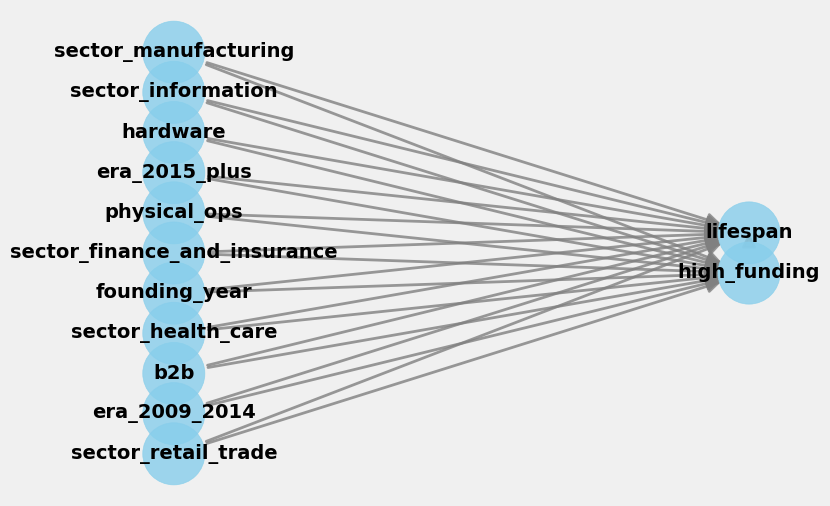

In [60]:
from dowhy import CausalModel

model = CausalModel(
    data=df_dw,
    treatment=[TREATMENT_DW],
    outcome=OUTCOME_DW,
    common_causes=COMMON_CAUSES,
)

model.view_model()

### identify effect

This step checks, from the causal graph, whether the effect of funding on lifespan can be estimated from the data and which adjustment to use.

DoWhy found a valid backdoor adjustment: the effect can be estimated by adjusting for the 11 confounders. It found no instrument or frontdoor path, which is expected because we did not define any. This only holds if no important confounder is missing from the data.

In [61]:
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                                                                       ↪
───────────────(E[lifespan|sector_retail_trade,era_2009_2014,b2b,sector_health ↪
d[high_funding]                                                                ↪

↪                                                                              ↪
↪ _care,founding_year,sector_finance_and_insurance,physical_ops,era_2015_plus, ↪
↪                                                                              ↪

↪                                                   
↪ hardware,sector_information,sector_manufacturing])
↪                                                   
Estimand assumption 1, Unconfoundedness: If U→{high_funding} and U→lifespan then P(lifespan|high_funding,sector_retail_trade,era_2009_2014,b2b,sector_health_care,founding_year,sector_finance_and_insurance,physical_ops,era_2015_plus,hardware,sec

### propensity score stratification

estimates each startup's probability of getting high funding from its confounders, groups startups with similar probabilities, and compares funded and unfunded startups within each group.

The estimated effect is 2.47 years, almost the same as the unadjusted gap of 2.45. The first run gave 2.33 and a convergence warning, which went away after centering `founding_year`. That the estimate moved shows this method is somewhat sensitive on 356 startups, so roughly 2.5 years.

In [62]:
estimate_ps = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.propensity_score_stratification",
)
print(estimate_ps)
print("Causal Estimate is " + str(estimate_ps.value))

*** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                                                                       ↪
───────────────(E[lifespan|sector_retail_trade,era_2009_2014,b2b,sector_health ↪
d[high_funding]                                                                ↪

↪                                                                              ↪
↪ _care,founding_year,sector_finance_and_insurance,physical_ops,era_2015_plus, ↪
↪                                                                              ↪

↪                                                   
↪ hardware,sector_information,sector_manufacturing])
↪                                                   
Estimand assumption 1, Unconfoundedness: If U→{high_funding} and U→lifespan then P(lifespan|high_funding,sector_retail_trade,era_2009_2014,b2b,sector_health_care,founding_year,sector_finance_and_i

### linear regression

regresses lifespan on funding and the confounders, and the coefficient on funding is the estimated effect. 

The estimated effect is 2.21 years (95% interval 1.59 to 2.82, p < 0.001). This is the same calculation as CausalML's LRSRegressor, so it is not an independent confirmation.

In [63]:
estimate_lin = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.linear_regression",
)
print(estimate_lin)
print("Causal Estimate is " + str(estimate_lin.value))

*** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                                                                       ↪
───────────────(E[lifespan|sector_retail_trade,era_2009_2014,b2b,sector_health ↪
d[high_funding]                                                                ↪

↪                                                                              ↪
↪ _care,founding_year,sector_finance_and_insurance,physical_ops,era_2015_plus, ↪
↪                                                                              ↪

↪                                                   
↪ hardware,sector_information,sector_manufacturing])
↪                                                   
Estimand assumption 1, Unconfoundedness: If U→{high_funding} and U→lifespan then P(lifespan|high_funding,sector_retail_trade,era_2009_2014,b2b,sector_health_care,founding_year,sector_finance_and_i

### refutation

Refutation tries to break the estimate: we change the data or the assumptions in ways that should not matter, or that should remove the effect, and check whether the estimate behaves accordingly. Passing does not prove the estimate is right, only that it did not fail these tests.

- Random common cause: adds a random variable as an extra confounder, and the estimate should barely change.
- Placebo treatment: replaces funding with a randomly shuffled version, and the estimate should drop to about zero.
- Data subset: re-estimates on a random 90% of the data, and the estimate should stay about the same.
- Unobserved common cause: adds a simulated hidden confounder of varying strength, and shows how much it takes to change the estimate.

In [64]:
import warnings
# Hide one harmless pandas deprecation warning that DoWhy repeats on every simulation

warnings.filterwarnings("ignore", message="Series.__getitem__ treating keys as positions")

res_random = model.refute_estimate(identified_estimand, estimate_lin,
                                   method_name="random_common_cause",
                                   show_progress_bar=False)
print(res_random)

Refute: Add a random common cause
Estimated effect:2.2078159405507174
New effect:2.208187590937757
p value:0.98



In [65]:
res_placebo = model.refute_estimate(identified_estimand, estimate_lin,
                                    method_name="placebo_treatment_refuter",
                                    placebo_type="permute",
                                    show_progress_bar=False)
print(res_placebo)

Refute: Use a Placebo Treatment
Estimated effect:2.2078159405507174
New effect:0.03800200529846104
p value:0.8400000000000001



In [66]:
res_subset = model.refute_estimate(identified_estimand, estimate_lin,
                                   method_name="data_subset_refuter",
                                   subset_fraction=0.9,
                                   show_progress_bar=False)
print(res_subset)

Refute: Use a subset of data
Estimated effect:2.2078159405507174
New effect:2.2061186958966448
p value:0.88



c:\Users\eglan\anaconda3\envs\causal\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\eglan\anaconda3\envs\causal\Lib\site-packages\numpy\_core\fromnumeric.py:4062: FutureWarning: The behavior of DataFrame.std with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return std(axis=axis, dtype=dtype, out=out, ddof=ddof, **kwargs)
c:\Users\eglan\anaconda3\envs\causal\Lib\site-packages\dowhy\causal_refuters\add_unobserved_common_cause.py:366: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  new_data.loc[rel_interv

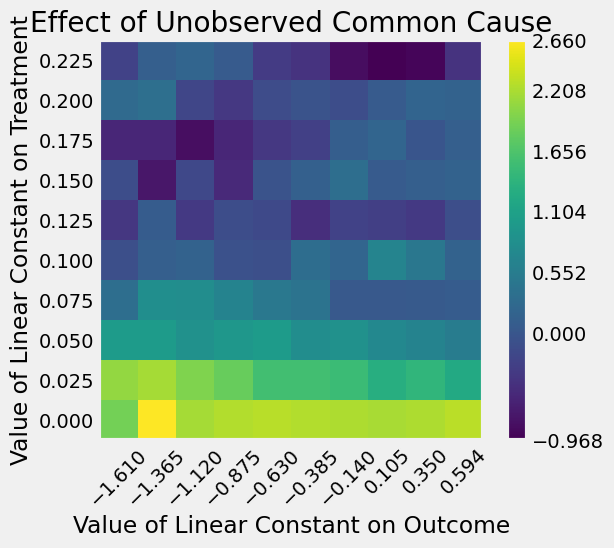

Refute: Add an Unobserved Common Cause
Estimated effect:2.2078159405507174
New effect:(np.float64(-0.9683872088667194), np.float64(2.659770455378009))



In [67]:
res_unobserved = model.refute_estimate(
    identified_estimand, estimate_lin,
    method_name="add_unobserved_common_cause",
    confounders_effect_on_treatment="binary_flip",
    confounders_effect_on_outcome="linear",
)
print(res_unobserved)

### Refutation results

| Refuter | Original | New | Result |
|---|---|---|---|
| Random common cause | 2.208 | 2.206 | Stable (p = 0.84) |
| Placebo treatment | 2.208 | 0.028 | Effect disappears, as expected (p = 0.98) |
| Data subset (90%) | 2.208 | 2.211 | Stable (p = 0.92) |
| Unobserved common cause | 2.208 | see heatmap | Sensitive to a moderately strong hidden confounder |

The first three tests show the estimate is stable: it doesn't change when we add noise, use 90% of the startups, or swap in a fake funding variable. They however don't test for a missing confounder, which is likely our biggest caveat. A random variable is just noise, while a real omitted factor would be tied to both funding and lifespan. For example, experienced founders might raise more money and also run their company better, so the startup lasts longer for reasons unrelated to the money.

The unobserved-common-cause test checks exactly that. DoWhy adds a simulated hidden factor to the data and sets how strongly it is tied to funding and to lifespan, then re-estimates the effect without adjusting for it. In the heatmap, the estimate stays near 2.2 years only when the hidden factor is barely tied to funding. As that tie grows, the estimate drops toward zero and can even turn negative. These strengths are simulation settings, not measurements, so we can't say how strong other metrics like founder experience, location or market size actually are in this data.

In conclusion, the positive effect of funding holds up against the checks we ran, but a strong enough hidden factor could remove it. This suggests that funding helps failed startups last longer, but isn't proof of it.

## Second treatment: losing to tech giants

**Hypothesis:** startups flagged as having lost to tech giants (`Giants = 1`) have shorter lifespans than comparable startups that did not.

- **Treatment:** `giants` (1 = lost to tech giants such as Google or Amazon)
- **Outcome:** `lifespan`
- **Common causes:** the same 11 confounders as before, plus `high_funding`, which we assume comes before the competitive outcome.

**Caveats:** the `Giants` flag was assigned after the fact from press coverage and post-mortems, so it involves judgment. Longer-lived startups also have more time to meet a giant, which could bias the estimate. Only 82 of 356 startups are in the comparison group (`Giants = 0`).

Note: The second treatment follows the same steps as the first (build the causal model, identify the effect, estimate it with linear regression and propensity score stratification, then run the refuters), so the explanations won't be repeated, only what is different will be reported.

In [68]:
#preparing data

df_g = df[["Giants", OUTCOME, TREATMENT] + CONFOUNDERS].copy()
df_g.columns = [clean(c) for c in df_g.columns]

df_g["giants"] = df_g["giants"].astype(bool)
df_g["founding_year"] = df_g["founding_year"] - 2010   # same centering as before

COMMON_CAUSES_G = [clean(c) for c in CONFOUNDERS] + ["high_funding"]

print(df_g.shape, "| Treated (giants):", df_g["giants"].sum())
print("Mean lifespan by group (raw, not causal):")
print(df_g.groupby("giants")["lifespan"].agg(["mean", "count"]).round(2))

(356, 14) | Treated (giants): 274
Mean lifespan by group (raw, not causal):
        mean  count
giants             
False   7.20     82
True    7.88    274


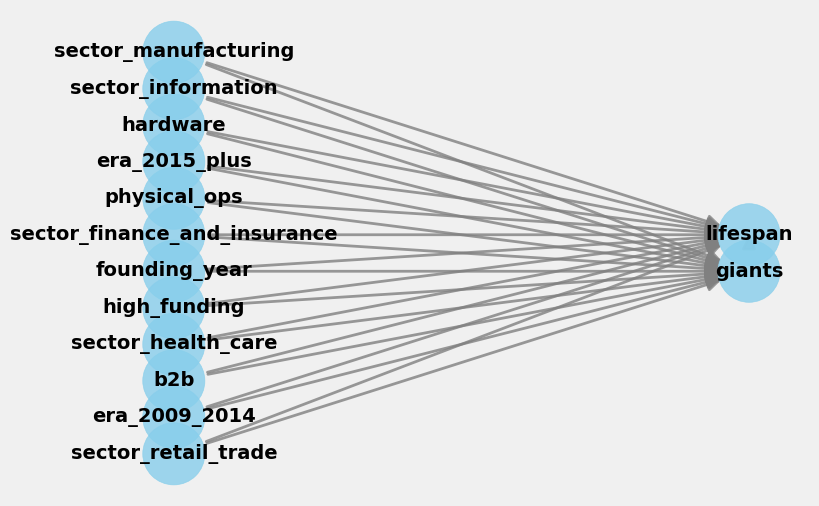

In [69]:
#creating model and graph

model_g = CausalModel(
    data=df_g,
    treatment=["giants"],
    outcome="lifespan",
    common_causes=COMMON_CAUSES_G,
)
model_g.view_model()

In [70]:
#identifying effect

identified_estimand_g = model_g.identify_effect(proceed_when_unidentifiable=True)
print(identified_estimand_g)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
    d                                                                          ↪
─────────(E[lifespan|sector_retail_trade,era_2009_2014,b2b,sector_health_care, ↪
d[giants]                                                                      ↪

↪                                                                              ↪
↪ high_funding,founding_year,sector_finance_and_insurance,physical_ops,era_201 ↪
↪                                                                              ↪

↪                                                          
↪ 5_plus,hardware,sector_information,sector_manufacturing])
↪                                                          
Estimand assumption 1, Unconfoundedness: If U→{giants} and U→lifespan then P(lifespan|giants,sector_retail_trade,era_2009_2014,b2b,sector_health_care,high_funding,founding_year,sector_finance_and_insurance,physical_ops,era_

In [71]:
#estimating with both methods

estimate_g_lin = model_g.estimate_effect(
    identified_estimand_g, method_name="backdoor.linear_regression")
print("Linear regression:", estimate_g_lin.value)

estimate_g_ps = model_g.estimate_effect(
    identified_estimand_g, method_name="backdoor.propensity_score_stratification")
print("Propensity stratification:", estimate_g_ps.value)

Linear regression: 0.4386316328531903
Propensity stratification: 0.5194991172815326


In [72]:
#linear regression

import statsmodels.api as sm

X_g = sm.add_constant(df_g[COMMON_CAUSES_G + ["giants"]].astype(float))
ols_g = sm.OLS(df_g["lifespan"].astype(float), X_g).fit()

print("Giants coefficient:", round(ols_g.params["giants"], 3))
print("95% interval:", ols_g.conf_int().loc["giants"].round(2).tolist())
print("p-value:", round(ols_g.pvalues["giants"], 3))

Giants coefficient: 0.439
95% interval: [-0.27, 1.15]
p-value: 0.226


In [73]:
#refuters

res_g_random = model_g.refute_estimate(identified_estimand_g, estimate_g_lin,
                                       method_name="random_common_cause", show_progress_bar=False)
print(res_g_random)

res_g_placebo = model_g.refute_estimate(identified_estimand_g, estimate_g_lin,
                                        method_name="placebo_treatment_refuter",
                                        placebo_type="permute", show_progress_bar=False)
print(res_g_placebo)

res_g_subset = model_g.refute_estimate(identified_estimand_g, estimate_g_lin,
                                       method_name="data_subset_refuter",
                                       subset_fraction=0.9, show_progress_bar=False)
print(res_g_subset)

Refute: Add a random common cause
Estimated effect:0.4386316328531903
New effect:0.4400637397649779
p value:0.8600000000000001

Refute: Use a Placebo Treatment
Estimated effect:0.4386316328531903
New effect:0.0157519648190922
p value:0.8600000000000001

Refute: Use a subset of data
Estimated effect:0.4386316328531903
New effect:0.4262696898834356
p value:0.92



c:\Users\eglan\anaconda3\envs\causal\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\eglan\anaconda3\envs\causal\Lib\site-packages\numpy\_core\fromnumeric.py:4062: FutureWarning: The behavior of DataFrame.std with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return std(axis=axis, dtype=dtype, out=out, ddof=ddof, **kwargs)
c:\Users\eglan\anaconda3\envs\causal\Lib\site-packages\dowhy\causal_refuters\add_unobserved_common_cause.py:366: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  new_data.loc[rel_interv

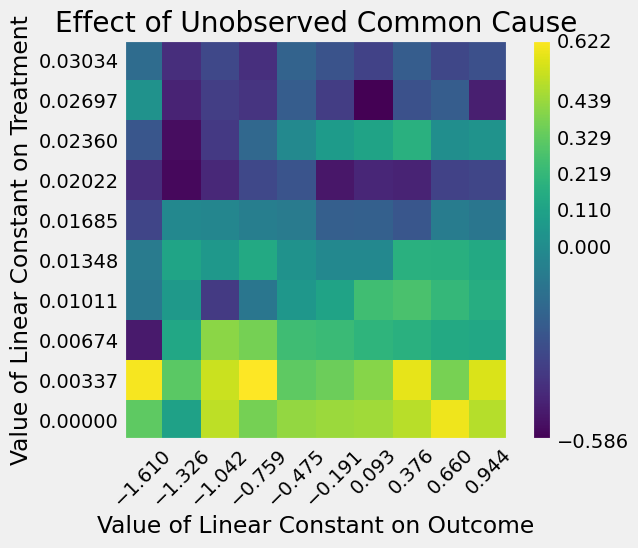

Refute: Add an Unobserved Common Cause
Estimated effect:0.4386316328531903
New effect:(np.float64(-0.5855202570153031), np.float64(0.6217116381483088))



In [74]:
res_g_unobserved = model_g.refute_estimate(
    identified_estimand_g, estimate_g_lin,
    method_name="add_unobserved_common_cause",
    confounders_effect_on_treatment="binary_flip",
    confounders_effect_on_outcome="linear",
)
print(res_g_unobserved)

In [75]:
X_f = sm.add_constant(df_dw[COMMON_CAUSES + [TREATMENT_DW]].astype(float))
ols_f = sm.OLS(df_dw["lifespan"].astype(float), X_f).fit()

print("High-funding coefficient:", round(ols_f.params[TREATMENT_DW], 3))
print("95% interval:", ols_f.conf_int().loc[TREATMENT_DW].round(2).tolist())
print("p-value:", round(ols_f.pvalues[TREATMENT_DW], 4))

High-funding coefficient: 2.208
95% interval: [1.59, 2.82]
p-value: 0.0


### Results for the second treatment: losing to tech giants

Startups flagged as losing to giants lasted 7.88 years on average (274 startups) against 7.20 for the others (82 startups), a raw gap of +0.68 years. After adjusting for the confounders and funding, the estimate falls to +0.44 years with linear regression and +0.52 with propensity score stratification. The sign is the opposite of what I expected: losing to giants does not appear to shorten lifespan.

The effect is small and not statistically clear. The regression 95% interval runs from -0.27 to 1.15 years (p = 0.23), so it includes zero. The data show no detectable effect in either direction, and a small negative effect cannot be ruled out. With only 82 startups in the comparison group, the test has little power.

The three refuters (random common cause, placebo treatment, data subset) pass: the estimate barely moves and the placebo gives about zero (-0.05). This shows the estimate is stable, not that the effect is real, since it is already close to zero. The unobserved-common-cause heatmap shows no clear pattern: the estimates stay between about -0.3 and +0.7 years, and the squares are noisy even where the hidden factor has no link to the treatment. It adds little beyond the interval.

One possible reason for the positive sign is reverse causality: a startup that survives longer has more time to meet a giant, so the flag may partly reflect survival time.Another reason could be that incumbents are slow to react so they allow for still a relatively long lifespan before being absorbed / losing out. I did not test either explanation.

# Conclusion

**Does more funding make failed startups last longer?** Probably yes, by about two years. Startups with high funding lasted 2.45 years longer than low-funded ones. After adjusting for founding year, era, sector and business model, the estimate is between 2.0 and 2.5 years depending on the method (2.21 with linear regression, 2.02 with XGBoost, 2.47 with propensity score stratification). Every method gives a positive effect, and the regression interval (1.59 to 2.82 years, p < 0.001) is well above zero. The estimate held up when I added a random confounder, used 90% of the data, or swapped in a fake funding variable, which gave about zero. It is not robust to a strong hidden confounder, though: in the sensitivity test, the estimate drops toward zero as the simulated factor's link to funding grows. Looking at subgroups, the benefit of funding seems larger for B2B startups (about 4 years against 1.6), while the hardware result is inconclusive. These subgroup results are exploratory.

**Does losing to tech giants shorten lifespan?** There is no evidence that it does. The adjusted effect is +0.44 years (interval -0.27 to 1.15, p = 0.23), which cannot be told apart from zero, and propensity score stratification gives a similar +0.52. The sign is the opposite of my hypothesis, but the interval includes zero, so I would not read it as a real benefit. One possible explanation is that startups that survive longer have more time to meet a giant, but I did not test this.

**Comparing the two.** Funding has a clear, sizable effect, while losing to giants has a small one that cannot be separated from zero. The comparison also shows why adjustment matters: for funding the raw gap shrank from 2.45 to about 2.2 years, and for giants from 0.68 to 0.44. The `Giants` result is less certain than the funding one, partly because only 82 startups are in its comparison group.

**Limitations**

- Every startup in the dataset failed, so the results only describe failed startups.
- Many other variables that could be associated to failure rate like founder experience, team size, location and market size are not measured and could bias both estimates.
- Both treatments may partly reflect survival time: startups that last longer have more time to raise money and to meet a giant.
- The business-model labels come from keyword rules with manual checks, and the `Giants` flag was assigned after the fact from press coverage.
- With 356 startups, the subgroup results are noisy.

There is a fundamental issue encountered, similar to my last assignment, when dealing with startup data. 
Firstly, every startup has a very unique path, its set of skills and knowledge differ through its team composition, similarly to the resources it can access from its founders, investor and partners network etc. so generalizing them is a complex task. 
Secondly, startup funding as a metric is actually a really opaque measure because investment decisions have been made with a set of information that is inaccessible and the value given is often 'paper value' as startups, at least in early stages, are giving funds without revenue or even fully formed business models. 
I remain commited to using analytics within the startup and VC field but have yet to find ways to bypass these fundamental complexities. 

## AI use disclosure

I used Claude (Sonnet 5.5) while working on this assignment. It helped with:

- **Data cleaning:** combining the six sector files, fixing the schema mismatch, removing duplicates, parsing the lifespan and funding columns, and building the business-model and era features from the company descriptions.
- **Setting up the environment:** working out why CausalML would not install, and creating a separate conda environment with compatible versions of CausalML, DoWhy and XGBoost.
- **Code:** helping write and debug the CausalML and DoWhy cells.
- **Formatting:** formatting the markdown explanations.

I chose the dataset, the research question and the hypotheses, ran all of the code myself,  reviewed the results and drafted the written interpretation. 